# Benchmark: recovering eight effect shapes

An additive model is useful when it returns the shape of each effect. This
study measures how closely each method recovers eight shapes that analysts
meet in practice, from a straight line to a jump and a narrow spike, at three
sample sizes, when no method is told which shape to expect.

Twelve predictors are independent and uniform on $(-1, 1)$. Eight have an
effect, each with a standard deviation of about 0.5 over the predictor's
range; four have none:

| Predictor | Shape | $f(x)$ |
|---|---|---|
| `s1` | line | $0.9x$ |
| `s2` | sine | $0.7\sin \pi x$ (one period) |
| `s3` | wiggle | $0.7\sin 3\pi x$ (three periods) |
| `s4` | jump | $1.0\,[x > 0.2]$ |
| `s5` | kink | $1.5\lvert x\rvert$ |
| `s6` | logistic | $0.6\tanh 8x$ (a steep sigmoid) |
| `s7` | exponential | $0.25\exp(2.5x)$ |
| `s8` | spike | $2\exp(-60x^2)$ (width about 0.13) |

The response is $y = \sum_{j=1}^8 f_j(s_j) + \varepsilon$ with standard
normal noise. Training samples have 300, 1,000 or 5,000 rows.

Every method receives the twelve columns and its default specification:
mboostrs `tune_mstop("y ~ .")` (a default P-spline per column, `mstop` by
5-fold cross-validation), the same followed by `gam_refit` (a REML refit of
the selected terms), and `autospec(budget=200)`, which chooses each column's
learner (`bbs`, `bols` or `btree`) from the data; mgcv `s(x)` per column with
REML, once with its default basis of ten functions per smooth and once with
`k = 24`, the size of mboostrs' default P-spline basis; pyGAM `s(x)` per column with its grid search; EBM with and without pair
terms; APLR; LightGBM tuned by early stopping.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the shape of each predictor's effect, and the prediction of the mean response |
| **Observed response** | simulated, Gaussian noise with sd 1 |
| **Estimand** | per predictor, the root mean squared difference between the method's centred partial dependence (mean prediction over 150 training rows with the predictor set to each of 41 grid values in $[-0.975, 0.975]$) and the true centred effect; RMSE of the predicted signal on 3,000 test rows |
| **Units** | response units |
| **Sampling unit** | one row; 300, 1,000 or 5,000 training rows and 3,000 test rows per seed |
| **Dependence** | independent rows and predictors |
| **Split / resampling unit** | a fresh test sample from the same design |
| **Tuning** | mboostrs: 5-fold CV of `mstop`; `autospec(budget=200)`; mgcv: REML; pyGAM: `gridsearch`; EBM, APLR: defaults; LightGBM: early stopping on a 20% validation split over 4, 15 and 31 leaves |
| **Uncertainty** | mean and standard error over 10 seeds |
| **Claim type** | methodological |
:::

The simulation and competitor protocol comes from `benches/bench_shapes.py`.
All existing autospec rows were rerun with native pre-exploration using
`python benches/refresh_autospec.py --studies shapes`. The page reads
`bench_shapes_preexploration.json`. Other methods retain their original results, measurement times and
build fingerprints; their rows are not relabelled as newly measured. These
mixed-date wall times describe workflow cost and do not establish a
same-build or fixed-workload speed ratio. The artifact's `protocol.refresh`
records the original file hash and the exact number of replaced rows.


In [1]:
import json
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl

bench = json.loads(Path("bench_shapes_preexploration.json").read_text())
records = [r for r in bench["results"] if "error" not in r and "failure" not in r]
failed = [r for r in bench["results"] if "error" in r or "failure" in r]
SHAPES = bench["protocol"]["shapes"]

example = next(r for r in records if r["method"] == "mboostrs" and r["n"] == 1000)
{"signal_rmse": round(example["signal_rmse"], 3),
 "effect_rmse": {k: round(v, 3) for k, v in example["effect_rmse"].items()},
 "fits": len(records), "failed": len(failed)}

{'signal_rmse': 0.351,
 'effect_rmse': {'s1': 0.085,
  's2': 0.059,
  's3': 0.149,
  's4': 0.13,
  's5': 0.122,
  's6': 0.089,
  's7': 0.085,
  's8': 0.164,
  'n1': 0.026,
  'n2': 0.069,
  'n3': 0.053,
  'n4': 0.099},
 'fits': 300,
 'failed': 0}

In [2]:
# One row per fit and predictor: the effect error, labelled by shape.
long = pl.DataFrame([
    {"n": r["n"], "method": r["method"], "seed": r["seed"], "predictor": k,
     "shape": SHAPES.get(k, "noise"), "error": v}
    for r in records for k, v in r["effect_rmse"].items()])
by_shape = (long.group_by("n", "method", "shape")
            .agg(pl.col("error").mean().alias("error"),
                 (pl.col("error").std() / pl.len().sqrt()).alias("se")))
signal = (pl.DataFrame([{k: r[k] for k in ("n", "method", "seed", "signal_rmse", "seconds")}
                        for r in records])
          .group_by("n", "method")
          .agg(pl.col("signal_rmse").mean(), (pl.col("signal_rmse").std() / pl.len().sqrt()).alias("se"),
               pl.col("seconds").mean()))


def err(n, method, shape):
    row = by_shape.filter((pl.col("n") == n) & (pl.col("method") == method) & (pl.col("shape") == shape))
    return float(row["error"][0])


def sig(n, method):
    return float(signal.filter((pl.col("n") == n) & (pl.col("method") == method))["signal_rmse"][0])

In [3]:
def sec(n, method):
    return float(signal.filter((pl.col("n") == n) & (pl.col("method") == method))["seconds"][0])

## Summary of results

The table gives each method's error in predicting the mean response at the
three sample sizes, its mean error over the eight true effect shapes, the
spurious effect it gives the four noise columns, and its fitting time.

In [4]:
from bench_tables import table as annotated

true_shapes = by_shape.filter(pl.col("shape") != "noise").group_by("n", "method").agg(
    pl.col("error").mean().alias("effect"))
noise = by_shape.filter(pl.col("shape") == "noise").select("n", "method", pl.col("error").alias("noise"))
per_n = signal.join(true_shapes, on=["n", "method"]).join(noise, on=["n", "method"])


def at(n, column, name):
    return per_n.filter(pl.col("n") == n).select("method", pl.col(column).alias(name))


summary = (at(300, "signal_rmse", "sig300").join(at(1000, "signal_rmse", "sig1000"), on="method")
           .join(at(5000, "signal_rmse", "sig5000"), on="method")
           .join(at(1000, "effect", "eff1000"), on="method")
           .join(at(5000, "effect", "eff5000"), on="method")
           .join(at(5000, "noise", "noise5000"), on="method")
           .join(at(5000, "seconds", "s5000"), on="method")
           .sort("sig1000"))

In [5]:
annotated(
    summary,
    title="Eight effect shapes: prediction and shape recovery by method",
    subtitle="Mean over 10 seeds; 12 predictors (8 with an effect, 4 noise), Gaussian noise sd 1",
    spanners={"Signal RMSE ↓": ["sig300", "sig1000", "sig5000"],
              "Effect error ↓": ["eff1000", "eff5000"]},
    labels={"sig300": "n=300", "sig1000": "n=1,000", "sig5000": "n=5,000",
            "eff1000": "n=1,000", "eff5000": "n=5,000", "noise5000": "noise ↓",
            "s5000": "s"},
    better={"sig300": "min", "sig1000": "min", "sig5000": "min", "eff1000": "min",
            "eff5000": "min", "noise5000": "min"},
    formats={"s5000": 1},
    notes=["Signal RMSE: root mean squared difference between the predicted and the true "
           "mean response on 3,000 test rows, in response units (the noise sd is 1). "
           "Effect error: root mean squared difference between a predictor's centred "
           "partial dependence and its true centred effect over 41 grid values, averaged "
           "over the eight true shapes (each has sd about 0.5).",
           "noise: the same error for the four predictors without an effect, at 5,000 "
           "rows, which is the size of the spurious effect given to them (0 is ideal). "
           "s: mean seconds per fit at 5,000 rows, including tuning.",
           "Bold: best in the column. Rows are sorted by signal RMSE at 1,000 rows. "
           "Standard errors of the signal RMSE over seeds appear in the next table; "
           "interpret close means against that simulation spread. Source: bench_shapes_preexploration.json, "
           "written by benches/bench_shapes.py."])

GT(_tbl_data=shape: (10, 8)
┌─────────────────┬──────────┬──────────┬──────────┬──────────┬──────────┬────────────┬────────────┐
│ method          ┆ sig300   ┆ sig1000  ┆ sig5000  ┆ eff1000  ┆ eff5000  ┆ noise5000  ┆ s5000      │
│ ---             ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---        ┆ ---        │
│ str             ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64        ┆ f64        │
╞═════════════════╪══════════╪══════════╪══════════╪══════════╪══════════╪════════════╪════════════╡
│ mboostrs + REML ┆ 0.469288 ┆ 0.292482 ┆ 0.151545 ┆ 0.090217 ┆ 0.046302 ┆ 0.011694   ┆ 7.300392   │
│ refit           ┆          ┆          ┆          ┆          ┆          ┆            ┆            │
│ mgcv k=24       ┆ 0.469624 ┆ 0.292972 ┆ 0.152025 ┆ 0.09032  ┆ 0.046755 ┆ 0.011733   ┆ 224.64051  │
│ mboostrs        ┆ 0.571112 ┆ 0.311728 ┆ 0.180699 ┆ 0.102176 ┆ 0.054058 ┆ 1.9984e-16 ┆ 138.310276 │
│ autospec        ┆          ┆          ┆          ┆          ┆          ┆            ┆            │
│ mgcv            ┆ 0.498209 ┆ 0.326833 ┆ 0.228449 ┆ 0.098582 ┆ 0.061491 ┆ 0.012148   ┆ 83.016277  │
│ mboostrs        ┆ 0.567255 ┆ 0.348519 ┆ 0.191522 ┆ 0.102518 ┆ 0.05613  ┆ 0.023106   ┆ 6.395894   │
│ pyGAM           ┆ 0.721933 ┆ 0.412523 ┆ 0.197734 ┆ 0.119833 ┆ 0.057657 ┆ 0.040874   ┆ 4.853561   │
│ EBM additive    ┆ 0.644316 ┆ 0.418434 ┆ 0.20749  ┆ 0.124115 ┆ 0.060406 ┆ 0.034521   ┆ 14.6333    │
│ EBM             ┆ 0.648455 ┆ 0.419732 ┆ 0.207044 ┆ 0.12314  ┆ 0.059578 ┆ 0.036099   ┆ 79.765495  │
│ LightGBM        ┆ 0.7425   ┆ 0.493826 ┆ 0.273861 ┆ 0.13824  ┆ 0.074732 ┆ 0.016657   ┆ 4.05724    │
│ APLR            ┆ 0.885231 ┆ 0.620629 ┆ 0.303404 ┆ 0.169481 ┆ 0.077082 ┆ 0.020917   ┆ 61.137985  │
└─────────────────┴──────────┴──────────┴──────────┴──────────┴──────────┴────────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x113149670>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='sig300', type=<ColInfoTypeEnum.default: 1>, column_label='n=300', column_align='right', column_width=None), ColInfo(var='sig1000', type=<ColInfoTypeEnum.default: 1>, column_label='n=1,000', column_align='right', column_width=None), ColInfo(var='sig5000', type=<ColInfoTypeEnum.default: 1>, column_label='n=5,000', column_align='right', column_width=None), ColInfo(var='eff1000', type=<ColInfoTypeEnum.default: 1>, column_label='n=1,000', column_align='right', column_width=None), ColInfo(var='eff5000', type=<ColInfoTypeEnum.default: 1>, column_label='n=5,000', column_align='right', column_width=None), ColInfo(var='noise5000', type=<ColInfoTypeEnum.default: 1>, column_label='noise ↓', column_align='right', column_width=None), ColInfo(var='s5000', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e242210>, _spanners=Spanners([SpannerInfo(spanner_id='Signal RMSE ↓', spanner_level=0, spanner_label='Signal RMSE ↓', spanner_units=None, spanner_pattern=None, vars=['sig300', 'sig1000', 'sig5000'], built=None), SpannerInfo(spanner_id='Effect error ↓', spanner_level=0, spanner_label='Effect error ↓', spanner_units=None, spanner_pattern=None, vars=['eff1000', 'eff5000'], built=None)]), _heading=Heading(title='Eight effect shapes: prediction and shape recovery by method', subtitle='Mean over 10 seeds; 12 predictors (8 with an effect, 4 noise), Gaussian noise sd 1', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10f311bb0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x113118110>, _source_notes=["Signal RMSE: root mean squared difference between the predicted and the true mean response on 3,000 test rows, in response units (the noise sd is 1). Effect error: root mean squared difference between a predictor's centred partial dependence and its true centred effect over 

## Prediction of the mean

The signal RMSE is the error of the predicted mean response on test rows
against the noise-free mean, so it excludes the noise the methods cannot
predict.

In [6]:
signal_wide = (signal.pivot(on="n", index="method", values="signal_rmse")
               .join(signal.pivot(on="n", index="method", values="se"), on="method", suffix=" se")
               .sort("1000"))
annotated(
    signal_wide.select("method", "300", "300 se", "1000", "1000 se", "5000", "5000 se"),
    title="Error of the predicted mean response",
    subtitle="Signal RMSE on 3,000 test rows, mean and standard error over 10 seeds (lower is better)",
    spanners={"n = 300": ["300", "300 se"], "n = 1,000": ["1000", "1000 se"],
              "n = 5,000": ["5000", "5000 se"]},
    labels={"300": "RMSE", "1000": "RMSE", "5000": "RMSE",
            "300 se": "se", "1000 se": "se", "5000 se": "se"},
    better={"300": "min", "1000": "min", "5000": "min"},
    formats={"300 se": 3, "1000 se": 3, "5000 se": 3},
    notes=["Signal RMSE: root mean squared difference between a method's predicted mean "
           "and the noise-free mean response, in response units; the noise sd is 1. "
           "se: standard error of the mean over seeds. Bold: lowest RMSE at that size."])

GT(_tbl_data=shape: (10, 7)
┌───────────────────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
│ method                ┆ 300      ┆ 300 se   ┆ 1000     ┆ 1000 se  ┆ 5000     ┆ 5000 se  │
│ ---                   ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ str                   ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞═══════════════════════╪══════════╪══════════╪══════════╪══════════╪══════════╪══════════╡
│ mboostrs + REML refit ┆ 0.469288 ┆ 0.01428  ┆ 0.292482 ┆ 0.007336 ┆ 0.151545 ┆ 0.00458  │
│ mgcv k=24             ┆ 0.469624 ┆ 0.014883 ┆ 0.292972 ┆ 0.007119 ┆ 0.152025 ┆ 0.00458  │
│ mboostrs autospec     ┆ 0.571112 ┆ 0.023727 ┆ 0.311728 ┆ 0.00768  ┆ 0.180699 ┆ 0.003852 │
│ mgcv                  ┆ 0.498209 ┆ 0.022673 ┆ 0.326833 ┆ 0.006946 ┆ 0.228449 ┆ 0.002447 │
│ mboostrs              ┆ 0.567255 ┆ 0.014321 ┆ 0.348519 ┆ 0.009538 ┆ 0.191522 ┆ 0.002985 │
│ pyGAM                 ┆ 0.721933 ┆ 0.018038 ┆ 0.412523 ┆ 0.011522 ┆ 0.197734 ┆ 0.004583 │
│ EBM additive          ┆ 0.644316 ┆ 0.014784 ┆ 0.418434 ┆ 0.010005 ┆ 0.20749  ┆ 0.003708 │
│ EBM                   ┆ 0.648455 ┆ 0.014424 ┆ 0.419732 ┆ 0.009697 ┆ 0.207044 ┆ 0.003333 │
│ LightGBM              ┆ 0.7425   ┆ 0.028023 ┆ 0.493826 ┆ 0.007837 ┆ 0.273861 ┆ 0.002982 │
│ APLR                  ┆ 0.885231 ┆ 0.013243 ┆ 0.620629 ┆ 0.009388 ┆ 0.303404 ┆ 0.007332 │
└───────────────────────┴──────────┴──────────┴──────────┴──────────┴──────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10f0a2990>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='300', type=<ColInfoTypeEnum.default: 1>, column_label='RMSE', column_align='right', column_width=None), ColInfo(var='300 se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None), ColInfo(var='1000', type=<ColInfoTypeEnum.default: 1>, column_label='RMSE', column_align='right', column_width=None), ColInfo(var='1000 se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None), ColInfo(var='5000', type=<ColInfoTypeEnum.default: 1>, column_label='RMSE', column_align='right', column_width=None), ColInfo(var='5000 se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e042ba0>, _spanners=Spanners([SpannerInfo(spanner_id='n = 300', spanner_level=0, spanner_label='n = 300', spanner_units=None, spanner_pattern=None, vars=['300', '300 se'], built=None), SpannerInfo(spanner_id='n = 1,000', spanner_level=0, spanner_label='n = 1,000', spanner_units=None, spanner_pattern=None, vars=['1000', '1000 se'], built=None), SpannerInfo(spanner_id='n = 5,000', spanner_level=0, spanner_label='n = 5,000', spanner_units=None, spanner_pattern=None, vars=['5000', '5000 se'], built=None)]), _heading=Heading(title='Error of the predicted mean response', subtitle='Signal RMSE on 3,000 test rows, mean and standard error over 10 seeds (lower is better)', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x1131bade0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x1131bb1a0>, _source_notes=["Signal RMSE: root mean squared difference between a method's predicted mean and the noise-free mean response, in response units; the noise sd is 1. se: standard error of the mean over seeds. Bold: lowest RMSE at that size."], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1131BB770>, mask=None), grpname=None, colname='300', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1131BB770>, mask=None), grpname=None, colname='300', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]),

The REML refit of the boosted model and mgcv with the same basis size
predict the mean equally well at every sample size: at 5,000 rows
{eval}`round(sig(5000, "mboostrs + REML refit"), 3)` for the refit and
{eval}`round(sig(5000, "mgcv k=24"), 3)` for mgcv with `k = 24` (at 300 rows
{eval}`round(sig(300, "mboostrs + REML refit"), 3)` and
{eval}`round(sig(300, "mgcv k=24"), 3)`). Both are penalized regression
splines with REML smoothing parameters, and with the same number of basis
functions they estimate the same curves. mgcv's default basis of ten
functions per smooth cannot follow the narrow spike: at 5,000 rows its error
is {eval}`round(sig(5000, "mgcv"), 3)`, behind the boosted fit
({eval}`round(sig(5000, "mboostrs"), 3)` for `tune_mstop("y ~ .")`). The
advantage of the mboostrs defaults here is the basis size, 24 functions with a
penalty that decides how many are used; mgcv at `k = 24` costs
{eval}`round(sec(5000, "mgcv k=24"))` seconds per fit at 5,000 rows against
{eval}`round(sec(5000, "mboostrs + REML refit"))` for the boosted fit and its
refit together. EBM, pyGAM, LightGBM and APLR trail at every size.
At 300 rows, autospec has signal error
{eval}`round(sig(300, "mboostrs autospec"), 3)`, close to the ordinary boosted
fit's {eval}`round(sig(300, "mboostrs"), 3)`. At 1,000 and 5,000 rows it lies
between the boosted fit and the REML refit. Early stopping still shrinks
its fitted effects even after selecting their shapes.

## Error by shape

The chart shows each method's effect error for each shape at 1,000 rows;
the table after it gives all three sample sizes.

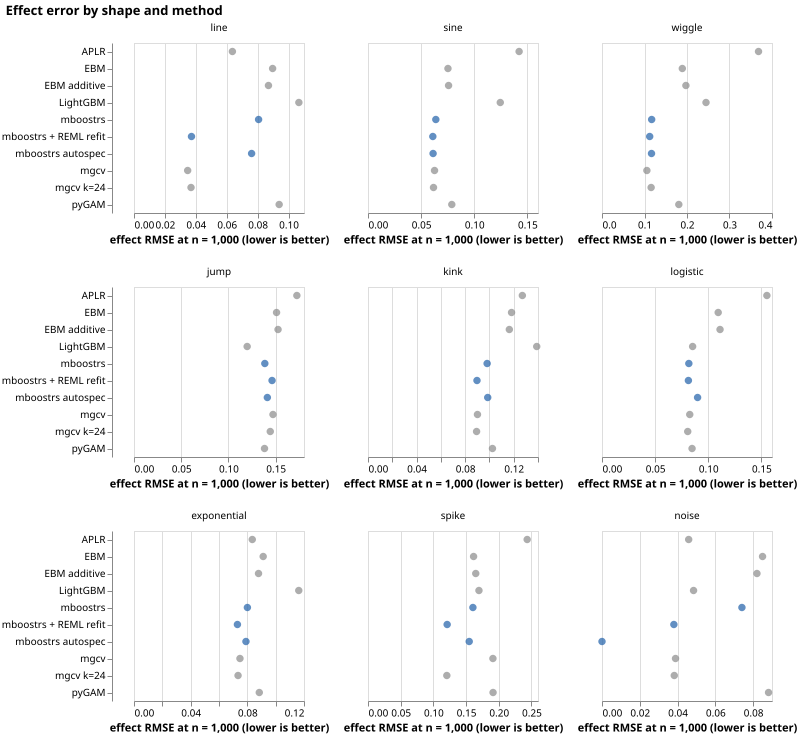

In [7]:
data = by_shape.filter(pl.col("n") == 1000).with_columns(
    pl.col("method").str.starts_with("mboostrs").alias("mboostrs"))
alt.Chart(data).mark_point(filled=True, size=55).encode(
    x=alt.X("error:Q", title="effect RMSE at n = 1,000 (lower is better)"),
    y=alt.Y("method:N", title=None),
    color=alt.Color("mboostrs:N", legend=None, scale=alt.Scale(range=["#8a8a8a", "#1f5fa8"])),
    facet=alt.Facet("shape:N", columns=3, title=None,
                    sort=["line", "sine", "wiggle", "jump", "kink", "logistic",
                          "exponential", "spike", "noise"]),
).resolve_scale(x="independent").properties(
    width=170, height=170, title="Effect error by shape and method")

In [8]:
shape_table = (by_shape.pivot(on="shape", index=["n", "method"], values="error")
               .sort("n", "method").with_columns(pl.col("n").map_elements(lambda n: f"n = {n:,}", return_dtype=pl.String).alias("size")))
smooth = ["line", "sine", "wiggle", "kink", "logistic", "exponential"]
display(annotated(
    shape_table.select("size", "method", *smooth),
    title="Effect error for the six smooth shapes",
    subtitle="Mean over 10 seeds of each predictor's effect RMSE (lower is better)",
    group="size", better={s: "min" for s in smooth},
    labels={"exponential": "exp."},
    notes=["Effect RMSE: root mean squared difference between the centred partial "
           "dependence and the true centred effect over 41 grid values in response "
           "units; each true effect has sd about 0.5. wiggle: three periods of a sine; "
           "exp.: 0.25 exp(2.5x). Bold: best within each sample size."]))
display(annotated(
    shape_table.select("size", "method", "jump", "spike", "noise"),
    title="Effect error for the jump, the spike and the noise columns",
    subtitle="Mean over 10 seeds of each predictor's effect RMSE (lower is better)",
    group="size", better={"jump": "min", "spike": "min", "noise": "min"},
    notes=["jump: a step of 1 at x = 0.2; spike: 2 exp(-60x²), width about 0.13; "
           "noise: mean over the four predictors without an effect, where the error is "
           "the size of the spurious effect. Bold: best within each sample size."]))

GT(_tbl_data=shape: (30, 8)
┌───────────┬─────────────────┬──────────┬──────────┬──────────┬──────────┬──────────┬─────────────┐
│ size      ┆ method          ┆ line     ┆ sine     ┆ wiggle   ┆ kink     ┆ logistic ┆ exponential │
│ ---       ┆ ---             ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---         │
│ str       ┆ str             ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64         │
╞═══════════╪═════════════════╪══════════╪══════════╪══════════╪══════════╪══════════╪═════════════╡
│ n = 300   ┆ APLR            ┆ 0.122374 ┆ 0.250755 ┆ 0.44618  ┆ 0.227229 ┆ 0.245548 ┆ 0.148769    │
│ n = 300   ┆ EBM             ┆ 0.135048 ┆ 0.154895 ┆ 0.302588 ┆ 0.143555 ┆ 0.162824 ┆ 0.143558    │
│ n = 300   ┆ EBM additive    ┆ 0.130455 ┆ 0.155105 ┆ 0.316056 ┆ 0.142615 ┆ 0.163987 ┆ 0.139595    │
│ n = 300   ┆ LightGBM        ┆ 0.158893 ┆ 0.182727 ┆ 0.34744  ┆ 0.194671 ┆ 0.157555 ┆ 0.186426    │
│ n = 300   ┆ mboostrs        ┆ 0.128822 ┆ 0.115689 ┆ 0.234407 ┆ 0.114188 ┆ 0.145282 ┆ 0.143897    │
│ …         ┆ …               ┆ …        ┆ …        ┆ …        ┆ …        ┆ …        ┆ …           │
│ n = 5,000 ┆ mboostrs + REML ┆ 0.009934 ┆ 0.029753 ┆ 0.047496 ┆ 0.040183 ┆ 0.044442 ┆ 0.032856    │
│           ┆ refit           ┆          ┆          ┆          ┆          ┆          ┆             │
│ n = 5,000 ┆ mboostrs        ┆ 0.022274 ┆ 0.027525 ┆ 0.055031 ┆ 0.041431 ┆ 0.050768 ┆ 0.033026    │
│           ┆ autospec        ┆          ┆          ┆          ┆          ┆          ┆             │
│ n = 5,000 ┆ mgcv            ┆ 0.011597 ┆ 0.029398 ┆ 0.041876 ┆ 0.041069 ┆ 0.044188 ┆ 0.033897    │
│ n = 5,000 ┆ mgcv k=24       ┆ 0.009992 ┆ 0.030219 ┆ 0.050797 ┆ 0.040267 ┆ 0.044316 ┆ 0.033411    │
│ n = 5,000 ┆ pyGAM           ┆ 0.03983  ┆ 0.037518 ┆ 0.053512 ┆ 0.045349 ┆ 0.045824 ┆ 0.042053    │
└───────────┴─────────────────┴──────────┴──────────┴──────────┴──────────┴──────────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x11324a630>, _boxhead=Boxhead([ColInfo(var='size', type=<ColInfoTypeEnum.row_group: 3>, column_label='size', column_align='left', column_width=None), ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='line', type=<ColInfoTypeEnum.default: 1>, column_label='line', column_align='right', column_width=None), ColInfo(var='sine', type=<ColInfoTypeEnum.default: 1>, column_label='sine', column_align='right', column_width=None), ColInfo(var='wiggle', type=<ColInfoTypeEnum.default: 1>, column_label='wiggle', column_align='right', column_width=None), ColInfo(var='kink', type=<ColInfoTypeEnum.default: 1>, column_label='kink', column_align='right', column_width=None), ColInfo(var='logistic', type=<ColInfoTypeEnum.default: 1>, column_label='logistic', column_align='right', column_width=None), ColInfo(var='exponential', type=<ColInfoTypeEnum.default: 1>, column_label='exp.', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x1131776e0>, _spanners=Spanners([]), _heading=Heading(title='Effect error for the six smooth shapes', subtitle="Mean over 10 seeds of each predictor's effect RMSE (lower is better)", preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x113249dc0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x1131b80e0>, _source_notes=['Effect RMSE: root mean squared difference between the centred partial dependence and the true centred effect over 41 grid values in response units; each true effect has sd about 0.5. wiggle: three periods of a sine; exp.: 0.25 exp(2.5x). Bold: best within each sample size.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1141B25D0>, mask=None), grpname=None, colname='line', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method"

GT(_tbl_data=shape: (30, 5)
┌───────────┬───────────────────────┬──────────┬──────────┬────────────┐
│ size      ┆ method                ┆ jump     ┆ spike    ┆ noise      │
│ ---       ┆ ---                   ┆ ---      ┆ ---      ┆ ---        │
│ str       ┆ str                   ┆ f64      ┆ f64      ┆ f64        │
╞═══════════╪═══════════════════════╪══════════╪══════════╪════════════╡
│ n = 300   ┆ APLR                  ┆ 0.241959 ┆ 0.452188 ┆ 0.044301   │
│ n = 300   ┆ EBM                   ┆ 0.200596 ┆ 0.283547 ┆ 0.130731   │
│ n = 300   ┆ EBM additive          ┆ 0.201849 ┆ 0.293317 ┆ 0.121633   │
│ n = 300   ┆ LightGBM              ┆ 0.169721 ┆ 0.299116 ┆ 0.061173   │
│ n = 300   ┆ mboostrs              ┆ 0.198979 ┆ 0.266321 ┆ 0.104214   │
│ …         ┆ …                     ┆ …        ┆ …        ┆ …          │
│ n = 5,000 ┆ mboostrs + REML refit ┆ 0.104396 ┆ 0.061355 ┆ 0.011694   │
│ n = 5,000 ┆ mboostrs autospec     ┆ 0.091206 ┆ 0.111202 ┆ 1.9984e-16 │
│ n = 5,000 ┆ mgcv                  ┆ 0.115724 ┆ 0.17418  ┆ 0.012148   │
│ n = 5,000 ┆ mgcv k=24             ┆ 0.102388 ┆ 0.062651 ┆ 0.011733   │
│ n = 5,000 ┆ pyGAM                 ┆ 0.104729 ┆ 0.092439 ┆ 0.040874   │
└───────────┴───────────────────────┴──────────┴──────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x113294cb0>, _boxhead=Boxhead([ColInfo(var='size', type=<ColInfoTypeEnum.row_group: 3>, column_label='size', column_align='left', column_width=None), ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='jump', type=<ColInfoTypeEnum.default: 1>, column_label='jump', column_align='right', column_width=None), ColInfo(var='spike', type=<ColInfoTypeEnum.default: 1>, column_label='spike', column_align='right', column_width=None), ColInfo(var='noise', type=<ColInfoTypeEnum.default: 1>, column_label='noise', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x113294fb0>, _spanners=Spanners([]), _heading=Heading(title='Effect error for the jump, the spike and the noise columns', subtitle="Mean over 10 seeds of each predictor's effect RMSE (lower is better)", preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x113295670>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x113295160>, _source_notes=['jump: a step of 1 at x = 0.2; spike: 2 exp(-60x²), width about 0.13; noise: mean over the four predictors without an effect, where the error is the size of the spurious effect. Bold: best within each sample size.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x11324ACF0>, mask=None), grpname=None, colname='jump', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x11324ACF0>, mask=None), grpname=None, colname='jump', rownum=5, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x11324ACF0>, mask=None), grpname=None, colname='jump', rownum=6, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x11324ACF0>, mask=None), grpname=None, colname='jump', rownum=14, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x11324ACF0>, mask=None), grpname=None, colname='jump', rownum=15, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x11324ACF0>, mask=None), grpname=None, colname='jump', rownum=16, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x113

Smooth shapes (line, sine, three-period sine, kink, logistic, exponential)
are recovered best by the penalized-regression fits, the mboostrs refit and
mgcv, which choose each curve's smoothness by REML; the boosted fits are
close behind. The jump is the one shape where the tree methods win at large
samples: LightGBM's error at 5,000 rows is
{eval}`round(err(5000, "LightGBM", "jump"), 3)` against
{eval}`round(err(5000, "mboostrs + REML refit", "jump"), 3)` for the refit,
because a regression tree represents a step exactly and a spline rounds it
off over a knot interval. `autospec` can fit the jump column as a tree
(`btree`); it does so when the tree lowers the held-out risk by 2% or by two
paired fold standard errors, and its error on the jump is
{eval}`round(err(5000, "mboostrs autospec", "jump"), 3)` at 5,000 rows. The spike
separates the smoothers by basis size: at 5,000 rows the refit's error is
{eval}`round(err(5000, "mboostrs + REML refit", "spike"), 3)`, mgcv's
{eval}`round(err(5000, "mgcv", "spike"), 3)` with its default basis and
{eval}`round(err(5000, "mgcv k=24", "spike"), 3)` with `k = 24`. The mean noise-column effect error for autospec is
{eval}`round(err(300, "mboostrs autospec", "noise"), 3)` at 300 rows and
{eval}`round(err(5000, "mboostrs autospec", "noise"), 3)` at 5,000 rows. Thus
deselection removes the noise effects at the larger size, but does not do so
on every small-sample fit.

## Estimated curves

The curves below are seed 0 at 1,000 rows for the three shapes that separate
the methods most, with the truth in black.

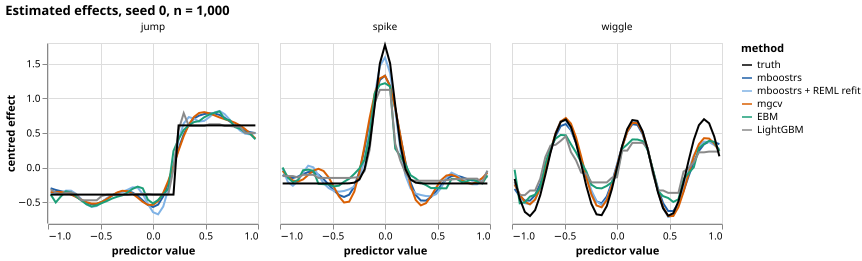

In [9]:
GRID = np.linspace(-0.975, 0.975, bench["protocol"]["grid"])
TRUTH = {"s3": lambda v: 0.7 * np.sin(3 * np.pi * v), "s4": lambda v: 1.0 * (v > 0.2),
         "s8": lambda v: 2 * np.exp(-60 * v ** 2)}
rows = []
for r in records:
    if r["n"] != 1000 or r["seed"] != 0 or not r.get("curves"):
        continue
    for key in TRUTH:
        for x, v in zip(GRID, r["curves"][key]):
            rows.append({"method": r["method"], "shape": SHAPES[key], "x": x, "effect": v})
for key, fn in TRUTH.items():
    truth = fn(GRID) - fn(GRID).mean()
    rows += [{"method": "truth", "shape": SHAPES[key], "x": x, "effect": v}
             for x, v in zip(GRID, truth)]
curves = pl.DataFrame(rows)
picked = ["truth", "mboostrs", "mboostrs + REML refit", "mgcv", "EBM", "LightGBM"]
alt.Chart(curves.filter(pl.col("method").is_in(picked))).mark_line().encode(
    x=alt.X("x:Q", title="predictor value"), y=alt.Y("effect:Q", title="centred effect"),
    color=alt.Color("method:N", sort=picked,
                    scale=alt.Scale(domain=picked, range=["black", "#1f5fa8", "#7fb2e5",
                                                         "#d95f02", "#1b9e77", "#8a8a8a"])),
    column=alt.Column("shape:N", title=None),
).properties(width=210, height=180, title="Estimated effects, seed 0, n = 1,000")

The truth is black. The boosted curve (dark blue) follows the three-period
sine with its peaks lowered, the REML refit (light blue) reaches them; both
round the jump off over about a tenth of the range, where LightGBM's steps
place it exactly but add steps elsewhere. mgcv's ten-function basis cannot
reach the top of the spike.

## Automatic specification

The refreshed autospec route uses one native tree ensemble to prioritize
columns and propose a restricted set of shape comparisons. The incumbent is
retained and ambiguous diagnostics leave every shape open. This is followed
by the same held-out comparison rule and deselection step as in the public
API. At 1,000 rows its signal RMSE is
{eval}`round(sig(1000, "mboostrs autospec"), 3)`.
The [pre-exploration benchmark](benchmark_preexploration.ipynb) separately
compares screening off, native and hessboost under a common protocol.

## Limitations

The predictors are independent and uniform and the noise Gaussian with
constant variance; correlated predictors are studied in the driver benchmark.
The mgcv `k = 24` variant fixes the basis size before fitting, so its comparison
with mboostrs also compares basis constructions. The broad noise-removal
claim applies to larger samples here; the 300-row result retains some noise
effects. Wall times were measured on different dates with other jobs running.
